In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import numpy as np
from tqdm import tqdm
import matplotlib.gridspec as gridspec  # To control widths

In [2]:
def bootstrap_block_freq(LWAA_tracked,n_iterations,n_sample):
    length = len(LWAA_tracked)
    freq_set = []
    for n in tqdm(range(n_iterations)):
        idxs = np.random.choice(np.arange(0,length,1),size=n_sample,replace=False)
        freq_set.append(xr.where(LWAA_tracked[idxs,:,:]>0,1,0).mean('time')*100)
    freq_set_da = xr.concat(freq_set,dim = 'realization')
    return freq_set_da.std('realization')*(np.sqrt(n_sample)/np.sqrt(len(LWAA_tracked)))

In [3]:
ds_baseline = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-11.nc')
ds_aa = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_KS_30_72,90/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-11.nc')

In [4]:
lat = ds_baseline['lat']
lon = ds_baseline['lon']
lentime = len(ds_baseline['time'])

### Local wave activity comparison

In [5]:
lwa_clim_zonmean_baseline = ds_baseline['dw_lwa'].mean('time').mean('lon')
lwa_clim_zonmean_aa = ds_aa['dw_lwa'].mean('time').mean('lon')
lwa_zonmean_baseline = ds_baseline['dw_lwa'].mean('lon')
lwa_zonmean_aa = ds_aa['dw_lwa'].mean('lon')
lwa_clim_baseline = ds_baseline['dw_lwa'].mean('time')
lwa_clim_aa = ds_aa['dw_lwa'].mean('time')

In [6]:
#computing error:
std_zonmean_baseline = lwa_zonmean_baseline.std('time')/np.sqrt(lentime)
std_zonmean_aa = lwa_zonmean_aa.std('time')/np.sqrt(lentime)
std_zonmean_diff = ((std_zonmean_baseline**2 + std_zonmean_aa**2)**0.5)

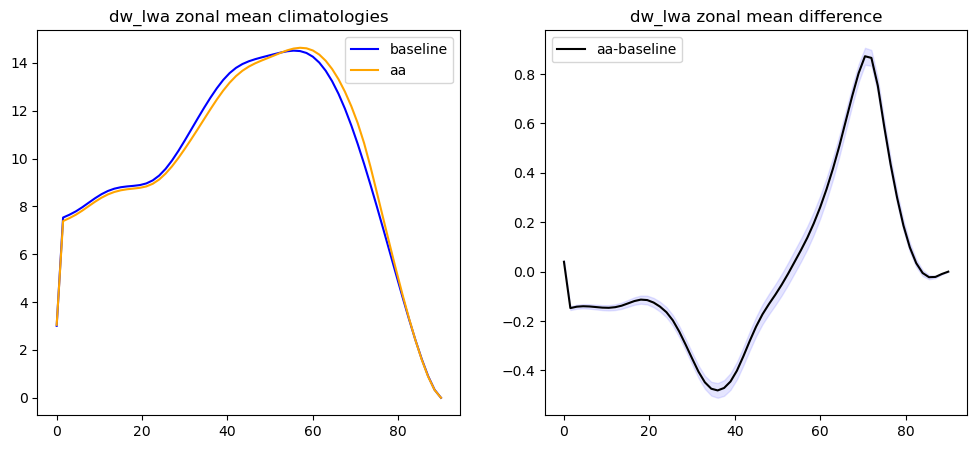

In [7]:
#LWA climatology zon_mean
fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0])

ax1.set_title('dw_lwa zonal mean climatologies')
ax1.plot(lat,lwa_clim_zonmean_baseline, color='blue', label='baseline')
ax1.plot(lat,lwa_clim_zonmean_aa, color='orange', label='aa')
ax1.legend()

ax2 = fig.add_subplot(gs[1])
diff = lwa_clim_zonmean_aa-lwa_clim_zonmean_baseline
ax2.set_title('dw_lwa zonal mean difference')
ax2.plot(lat,diff, color = 'black', label= 'aa-baseline')
ax2.fill_between(lat,diff - std_zonmean_diff, diff + std_zonmean_diff, color='blue', alpha=0.1)
plt.legend()

### Blocking frequency comparison

In [8]:
block_freq_zonmean_baseline = ds_baseline['LWAA_freq'].mean('lon')
block_freq_zonmean_aa = ds_aa['LWAA_freq'].mean('lon')

In [9]:
block_freq_std_baseline = bootstrap_block_freq(ds_baseline['LWAA_tracked'],30,1000)
block_freq_std_aa = block_freq_std_baseline
block_freq_std_diff = 2* block_freq_std_baseline

  0%|          | 0/30 [00:00<?, ?it/s]

100%|██████████| 30/30 [00:08<00:00,  3.58it/s]


In [10]:
block_freq_std_zonmean_diff = block_freq_std_diff.mean('lon')

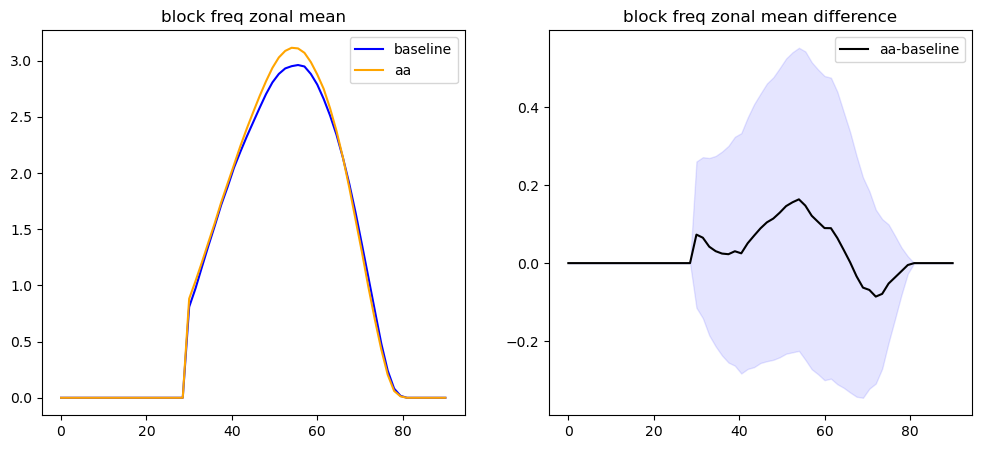

In [11]:
#LWA climatology zon_mean
fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0])

ax1.set_title('block freq zonal mean')
ax1.plot(lat,block_freq_zonmean_baseline, color='blue', label='baseline')
ax1.plot(lat,block_freq_zonmean_aa, color='orange', label='aa')
ax1.legend()

ax2 = fig.add_subplot(gs[1])
diff = block_freq_zonmean_aa-block_freq_zonmean_baseline
ax2.set_title('block freq zonal mean difference')
ax2.plot(lat,diff, color = 'black', label= 'aa-baseline')
ax2.fill_between(lat,diff - block_freq_std_zonmean_diff, diff + block_freq_std_zonmean_diff, color='blue', alpha=0.1)
plt.legend()

### Blocking frequency 2D comparison

In [12]:
block_freq_baseline = ds_baseline['LWAA_freq']
block_freq_aa = ds_aa['LWAA_freq']

<a list of 6 text.Text objects>

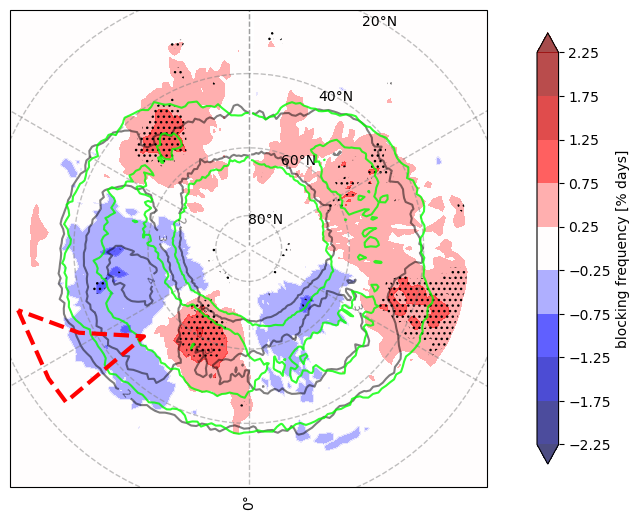

In [13]:
fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(8,8),subplot_kw={'projection': ccrs.NorthPolarStereo()})
extent =[-180,180,25,90]

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

#PLOT 1

ax.set_extent(extent, ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

cont_range = np.arange(-2.25,2.3,0.5)#/5
cont_levels = np.arange(2,10,1)#/5

diff = block_freq_aa-block_freq_baseline

gl.top_labels=False
gl.right_labels=False
cont = ax.contourf(lon,lat,diff,
                   cont_range,
                   extent=[0,90,-180,180],
                   extend='both',
                   transform = ccrs.PlateCarree(),
                   alpha=0.7,
                   cmap = "seismic")
sig = np.abs(diff) > 2*block_freq_std_diff
hatchings = ax.contourf(lon, lat, sig, levels=[0.5, 1.5], hatches=[None, "..."],
            colors="none", extend="both", transform=ccrs.PlateCarree())

cont_base = ax.contour(lon,lat,block_freq_baseline,
                         cont_levels,
                          colors = 'black',
                          alpha = 0.5,
                         transform= ccrs.PlateCarree())
cont_aa = ax.contour(lon,lat,block_freq_aa,
                         cont_levels,
                          colors = 'lime',
                          alpha = 0.8,
                         transform= ccrs.PlateCarree())

cbar = plt.colorbar(cont, shrink=0.7,orientation='vertical',label="blocking frequency [% days]",pad=0.08)
ax.plot(lons, lats, linestyle='--',linewidth=3, color='red', transform=ccrs.PlateCarree())

ax.clabel(cont_base, cont_base.levels, inline=True, fontsize=8)


### Comparing FC

In [14]:
ds_FC_baseline = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/FC_1.5x1.5_2-11.nc')
ds_FC_aa = xr.open_dataset('/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_KS_30_72,90/tot/FC_1.5x1.5_2-11.nc')

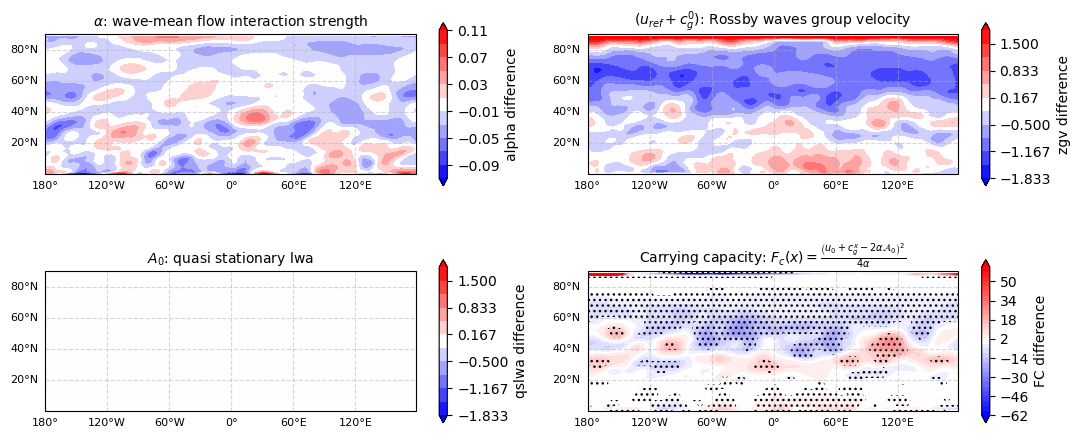

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig, axs = plt.subplots(ncols=2, nrows=2, subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(11, 5))
axs = axs.flatten()

lon = ds_FC_aa['lon']
lat = ds_FC_aa['lat']

# Plot each field and store the contourf object
fields = ['alpha', 'zgv', 'qslwa', 'FC']
titles = [r'$\alpha$: wave-mean flow interaction strength', '$(u_{ref} + c^0_g)$: Rossby waves group velocity', '$A_0$: quasi stationary lwa', 'Carrying capacity: ' + r'$F_c(x) = \frac{\left( u_0 + c_g^x - 2\alpha \mathcal{A}_0 \right)^2}{4\alpha}$']
levels = [np.arange(-0.11,0.12,0.02),np.arange(-5.5,5.6,1)/3,np.arange(-5.5,5.6,1)/3,np.arange(-31,32,2)*2]

for i, var in enumerate(fields):
    ax = axs[i]
    data = ds_FC_aa[var] - ds_FC_baseline[var]
    im = ax.contourf(lon, lat, data,
                     levels = levels[i] ,
                     cmap='bwr',extend='both')
    if var == 'FC':
        FC_std = np.sqrt(2)*ds_FC_aa['FC_std']
        sig = (np.abs(data) > 2*FC_std) * (np.abs(data) > 1)
        hatchings = ax.contourf(lon, lat, sig, levels=[0.5, 1.5], hatches=[None, "..."],
        colors="none", extend="both", transform=ccrs.PlateCarree())
    
    # Add colorbar specific to this subplot
    cbar = fig.colorbar(im, ax=ax, orientation='vertical', shrink=0.7)
    cbar.set_label(f"{var} difference")
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    ax.set_aspect(1.5)
    ax.set_title(titles[i], fontsize=10)

plt.tight_layout()
plt.show()


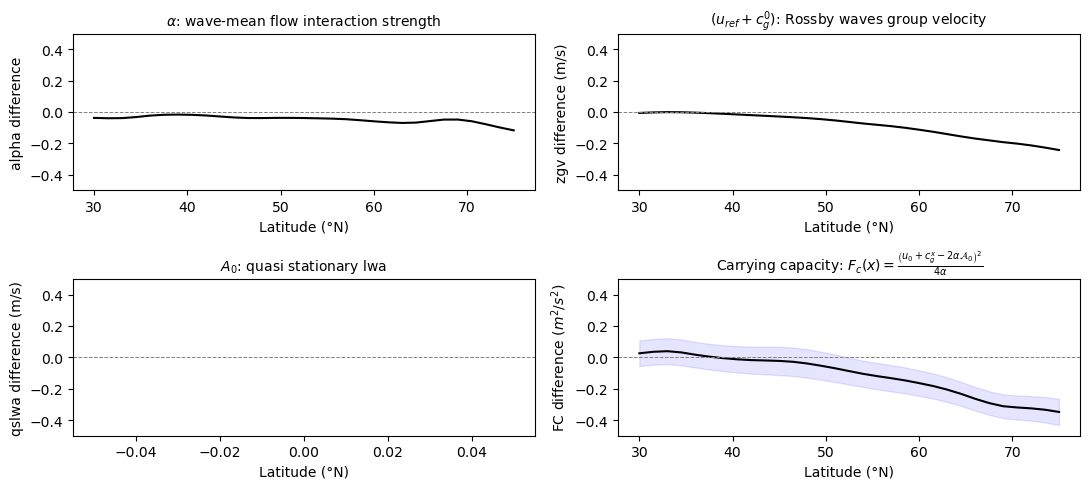

In [16]:
# same plot as before but with zonally averaged fields

fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(11, 5))

axs = axs.flatten()

# Plot each field and store the contourf object 

fields = ['alpha', 'zgv', 'qslwa', 'FC']
titles = [r'$\alpha$: wave-mean flow interaction strength', '$(u_{ref} + c^0_g)$: Rossby waves group velocity', '$A_0$: quasi stationary lwa', 'Carrying capacity: ' + r'$F_c(x) = \frac{\left( u_0 + c_g^x - 2\alpha \mathcal{A}_0 \right)^2}{4\alpha}$']
levels = [np.arange(-0.11,0.12,0.02),np.arange(-5.5,5.6,1)/3,np.arange(-5.5,5.6,1)/3,np.arange(-31,32,2)*2]

# Limit the latitude range
lat_range = (lat >= 30) & (lat <= 75)

#average the fields zonally

for i, var in enumerate(fields):
    ax = axs[i]
    data = ((ds_FC_aa[var] - ds_FC_baseline[var])/ds_FC_baseline[var].mean('lon').broadcast_like(ds_FC_baseline[var])).mean('lon')
    data = data.where(lat_range, drop=True)  # Filter data to the latitudinal range
    lat_filtered = lat[lat_range]  # Filter latitudes to the range [30, 75]
    
    im = ax.plot(lat_filtered, data, color='black')
    if var == 'FC':
        FC_std = (np.sqrt(2)*ds_FC_aa['FC_std']).mean('lon')/ds_FC_baseline[var].mean('lon')
        FC_std = FC_std.where(lat_range, drop=True)  # Filter FC_std to the latitudinal range
        FC_std = np.where(FC_std > 100, 0, FC_std)        
        sig = (np.abs(data) > 2*FC_std) * (np.abs(data) > 1)
        ax.fill_between(lat_filtered, data - 2*FC_std, data + 2*FC_std, color='blue', alpha=0.1)
    
    ax.set_title(titles[i], fontsize=10)
    ax.set_xlabel('Latitude (°N)')
    ax.set_ylim(-0.5,0.5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.7)
    # add the units
    if var == 'alpha':
        ax.set_ylabel(f"{var} difference")
    elif var in ['zgv', 'qslwa']:
        ax.set_ylabel(f"{var} difference (m/s)")
    elif var == 'FC':
        ax.set_ylabel(f"{var} difference ($m^2/s^2$)")
    #ax.set_aspect(1.5)

plt.tight_layout()
plt.show()

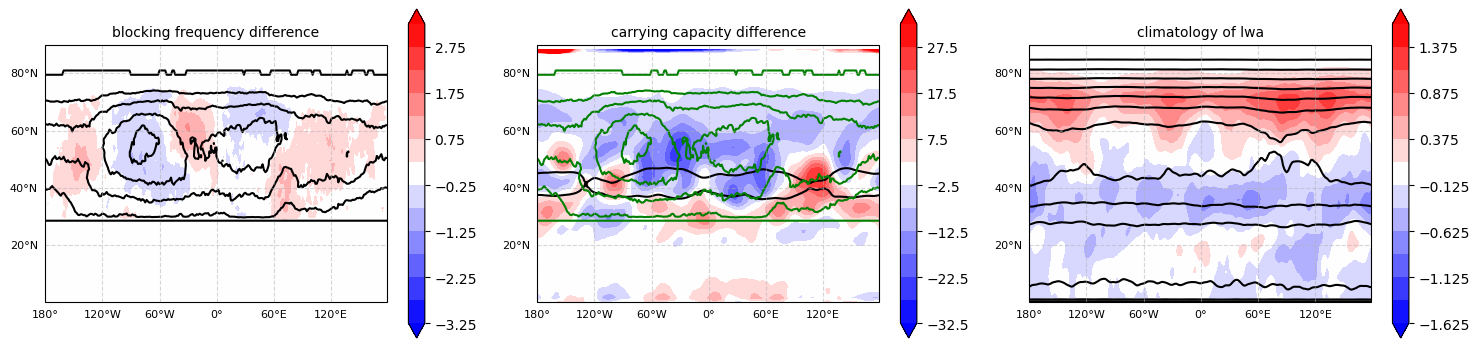

In [17]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

#cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ds_aa['qslwa'])

fig, axs = plt.subplots(ncols=3, nrows=1, subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(15, 5))
axs = axs.flatten()

#lon = ds_blocks_aa['lon'][:144]
#lat = ds_blocks_aa['lat']

block_freq_aa = ds_aa['LWAA_freq']
block_freq_baseline = ds_baseline['LWAA_freq']
#qslwa_diff = ds_FC_aa['qslwa'] - ds_FC_baseline['qslwa']
FC_aa = ds_FC_aa['FC']
FC_baseline = ds_FC_baseline['FC']
lwa_clim_aa = ds_aa['dw_lwa'].mean('time')
lwa_clim_baseline = ds_baseline['dw_lwa'].mean('time')

# Plot each field and store the contourf object
fields = [block_freq_aa-block_freq_baseline,FC_aa-FC_baseline,lwa_clim_aa-lwa_clim_baseline]
fields2 = [block_freq_baseline,FC_baseline,lwa_clim_baseline]
titles = ['blocking frequency difference', 'carrying capacity difference','climatology of lwa']
levels = [np.arange(-3.25,3.3,0.5),np.arange(-32.5,33,5),np.arange(-32.5,33,5)/20]
levels2 = [np.arange(0,12,1),np.arange(150,300,30),np.arange(0,120,10)/5]

for i, var in enumerate(fields):
    ax = axs[i]
    ax.set_aspect(3)
    data = fields[i]
    im = ax.contourf(lon, lat, data, levels = levels[i] ,cmap='bwr',extend='both')
    im2 = ax.contour(lon,lat, fields2[i],levels = levels2[i],colors='black')
    if i == 1:
        im3 = ax.contour(lon,lat,fields2[0],levels=levels2[0],colors='green')
    # Add colorbar specific to this subplot
    cbar = fig.colorbar(im, ax=ax, orientation='vertical', shrink=0.7)
    #cbar.set_label(f"{var} difference")
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    
    ax.set_title(titles[i], fontsize=10)

plt.tight_layout()
plt.show()

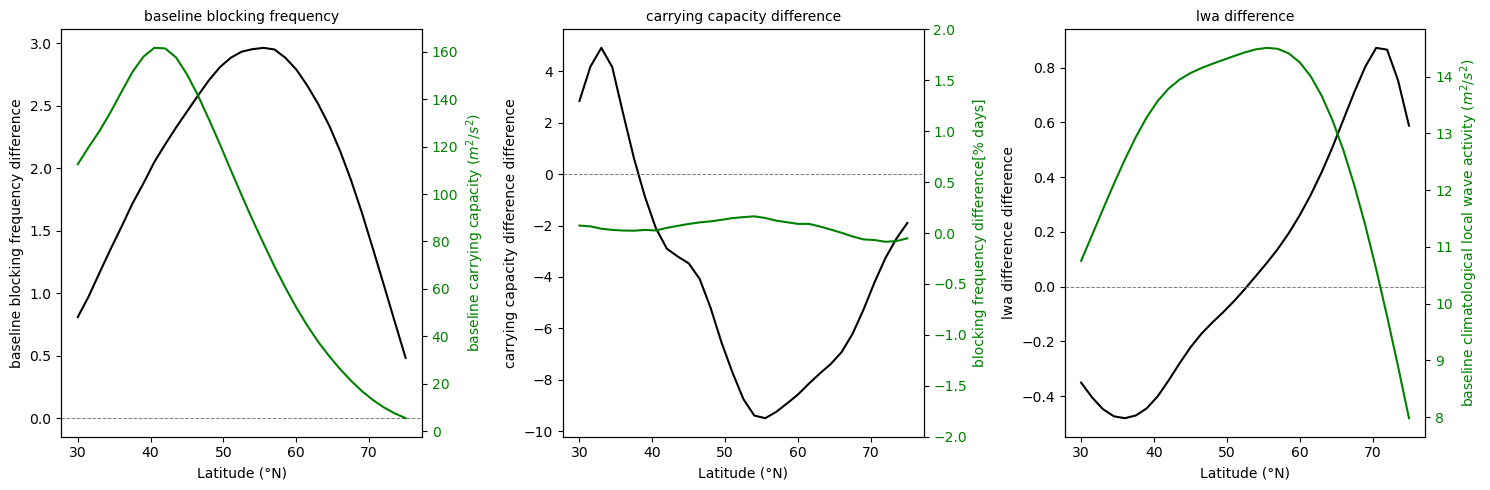

In [18]:
# Limit the latitude range
lat_range = (lat >= 30) & (lat <= 75)

# Plot each field and store the plot object 
fields = [block_freq_baseline, FC_aa - FC_baseline, lwa_clim_aa - lwa_clim_baseline]
titles = ['baseline blocking frequency', 'carrying capacity difference', 'lwa difference']

fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(15, 5))
axs = axs.flatten()

for i, var in enumerate(fields):
  ax = axs[i]
  data = var.mean('lon').where(lat_range, drop=True)  # Average zonally and filter by latitude
  lat_filtered = lat[lat_range]  # Filter latitudes to the range [30, 75]

  ax.plot(lat_filtered, data, color='black')
  ax.set_title(titles[i], fontsize=10)
  ax.set_xlabel('Latitude (°N)')
  ax.axhline(0, color='gray', linestyle='--', linewidth=0.7)
  ax.set_ylabel(f"{titles[i]} difference", color='black')
  ax.tick_params(axis='y', labelcolor='black')
  #ax.set_ylim(-20,20)

  if i == 2:
    field = lwa_clim_baseline.mean('lon').where(lat_range, drop=True)
    # set up the plot so that it has two y axis (on the left and on the right). The first one refers to the field, the second one to the blocking frequency
    ax2 = ax.twinx()
    ax2.plot(lat_filtered,field, color='green', label='blocking freq baseline')
    ax2.set_ylabel('baseline climatological local wave activity ($m^2/s^2$)', color='green')
    ax2.tick_params(axis='y', labelcolor='green')
    #ax2.set_ylim(-2,2)

  if i == 1:
    field = (block_freq_aa-block_freq_baseline).mean('lon').where(lat_range, drop=True)
    # set up the plot so that it has two y axis (on the left and on the right). The first one refers to the field, the second one to the blocking frequency
    ax2 = ax.twinx()
    ax2.plot(lat_filtered,field, color='green', label='blocking freq baseline')
    ax2.set_ylabel('blocking frequency difference[% days]', color='green')
    ax2.tick_params(axis='y', labelcolor='green')
    ax2.set_ylim(-2,2)

  if i == 0:
    field = FC_baseline.mean('lon').where(lat_range, drop=True)
    # set up the plot so that it has two y axis (on the left and on the right). The first one refers to the field, the second one to the blocking frequency
    ax2 = ax.twinx()
    ax2.plot(lat_filtered,field, color='green', label='blocking freq baseline')
    ax2.set_ylabel('baseline carrying capacity ($m^2/s^2$)', color='green')
    ax2.tick_params(axis='y', labelcolor='green')
    #ax2.set_ylim(-2,2)

plt.tight_layout()
plt.show()
